# 
**Bridge Condition Prediction System**

**Sprint 1: Data Understanding & Preprocessing**

## Step 1: Data Collection & Loading

In [1]:
import pandas as pd

df = pd.read_csv("../data/bridge_data.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset shape: (720, 5)
Columns: ['Age_of_Bridge', 'Traffic_Volume', 'Material_Type', 'Maintenance_Level', 'Bridge_Condition']


The dataset has 720 rows and 5 columns: 4 features (`Age_of_Bridge`, `Traffic_Volume`, `Material_Type`, `Maintenance_Level`) and the target `Bridge_Condition`.

## Step 2: Initial Data Inspection

In [2]:
print(df.head())
print(df.tail())

   Age_of_Bridge  Traffic_Volume Material_Type Maintenance_Level  \
0             80              60      Concrete   No-Maintainance   
1             44            2516         Steel         Bi-Annual   
2             61            4406      Concrete            Annual   
3             93            2082         Steel   No-Maintainance   
4             62            4159         Steel   No-Maintainance   

   Bridge_Condition  
0                 0  
1                 0  
2                 1  
3                 1  
4                 0  
     Age_of_Bridge  Traffic_Volume Material_Type Maintenance_Level  \
715              6            2964      Concrete            Annual   
716             90            3637      Concrete   No-Maintainance   
717             42            2134      Concrete            Annual   
718             92             778         Steel   No-Maintainance   
719             15            1391         Steel         Bi-Annual   

     Bridge_Condition  
715           

In [3]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Age_of_Bridge      720 non-null    int64
 1   Traffic_Volume     720 non-null    int64
 2   Material_Type      720 non-null    str  
 3   Maintenance_Level  720 non-null    str  
 4   Bridge_Condition   720 non-null    int64
dtypes: int64(3), str(2)
memory usage: 40.0 KB


In [4]:
print("\nStatistical Summary:")
print(df.describe())


Statistical Summary:
       Age_of_Bridge  Traffic_Volume  Bridge_Condition
count     720.000000      720.000000        720.000000
mean       49.033333     2420.827778          0.140278
std        29.469467     1423.863663          0.347516
min         1.000000       51.000000          0.000000
25%        23.000000     1106.000000          0.000000
50%        49.000000     2377.000000          0.000000
75%        75.000000     3605.000000          0.000000
max        99.000000     4994.000000          1.000000


Bridge age ranges from 1 to 99 years, while traffic volume ranges from 51 to 4,994. The average bridge age is approximately 49 years and the average traffic volume is approximately 2,421.

In [5]:
print("\nMaterial Types:")
print(df["Material_Type"].unique())

print("\nMaintenance Levels:")
print(df["Maintenance_Level"].unique())

print("\nBridge Condition Counts:")
print(df["Bridge_Condition"].value_counts())


Material Types:
<ArrowStringArray>
['Concrete', 'Steel']
Length: 2, dtype: str

Maintenance Levels:
<ArrowStringArray>
['No-Maintainance', 'Bi-Annual', 'Annual']
Length: 3, dtype: str

Bridge Condition Counts:
Bridge_Condition
0    619
1    101
Name: count, dtype: int64


`Material_Type` has 2 categories and `Maintenance_Level` has 3. The label `No-Maintainance` is misspelled and is fixed in Step 3. The raw target is imbalanced (619 poor vs 101 good); this is re-checked after cleaning.

In [6]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Age_of_Bridge        0
Traffic_Volume       0
Material_Type        0
Maintenance_Level    0
Bridge_Condition     0
dtype: int64


There are no missing values, so no imputation is needed. All data types are already correct.

## Step 3: Data Cleaning

In [7]:
print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nTarget of duplicated rows:")
print(df[df.duplicated(keep=False)]["Bridge_Condition"].value_counts())


Duplicate Rows:
128

Target of duplicated rows:
Bridge_Condition
0    215
Name: count, dtype: int64


In [8]:
df = df.drop_duplicates().reset_index(drop=True)

print("\nShape after removing duplicates:")
print(df.shape)

print("\nBridge Condition Counts after cleaning:")
print(df["Bridge_Condition"].value_counts())


Shape after removing duplicates:
(592, 5)

Bridge Condition Counts after cleaning:
Bridge_Condition
0    491
1    101
Name: count, dtype: int64


128 duplicate records were removed, reducing the dataset from 720 to 592 unique records. All duplicates were poor-condition bridges, so all 101 good bridges were kept. After cleaning the target is **491 poor vs 101 good (about 17% good)**, so it is imbalanced. Model evaluation should use precision, recall, F1-score and the confusion matrix rather than accuracy alone.

In [9]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
df["maintenance_level"] = df["maintenance_level"].replace({"No-Maintainance": "No-Maintenance"})

print("\nStandardized Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)


Standardized Column Names:
['age_of_bridge', 'traffic_volume', 'material_type', 'maintenance_level', 'bridge_condition']

Data Types:
age_of_bridge        int64
traffic_volume       int64
material_type          str
maintenance_level      str
bridge_condition     int64
dtype: object


In [10]:
df.to_csv("../data/bridge_data_clean.csv", index=False)
print("Clean dataset saved:", df.shape)

Clean dataset saved: (592, 5)


Column names are standardized, the category spelling is fixed, and the clean dataset is saved as `bridge_data_clean.csv`.

## Step 4: Exploratory Data Analysis (EDA)

### 4.1 Univariate Analysis

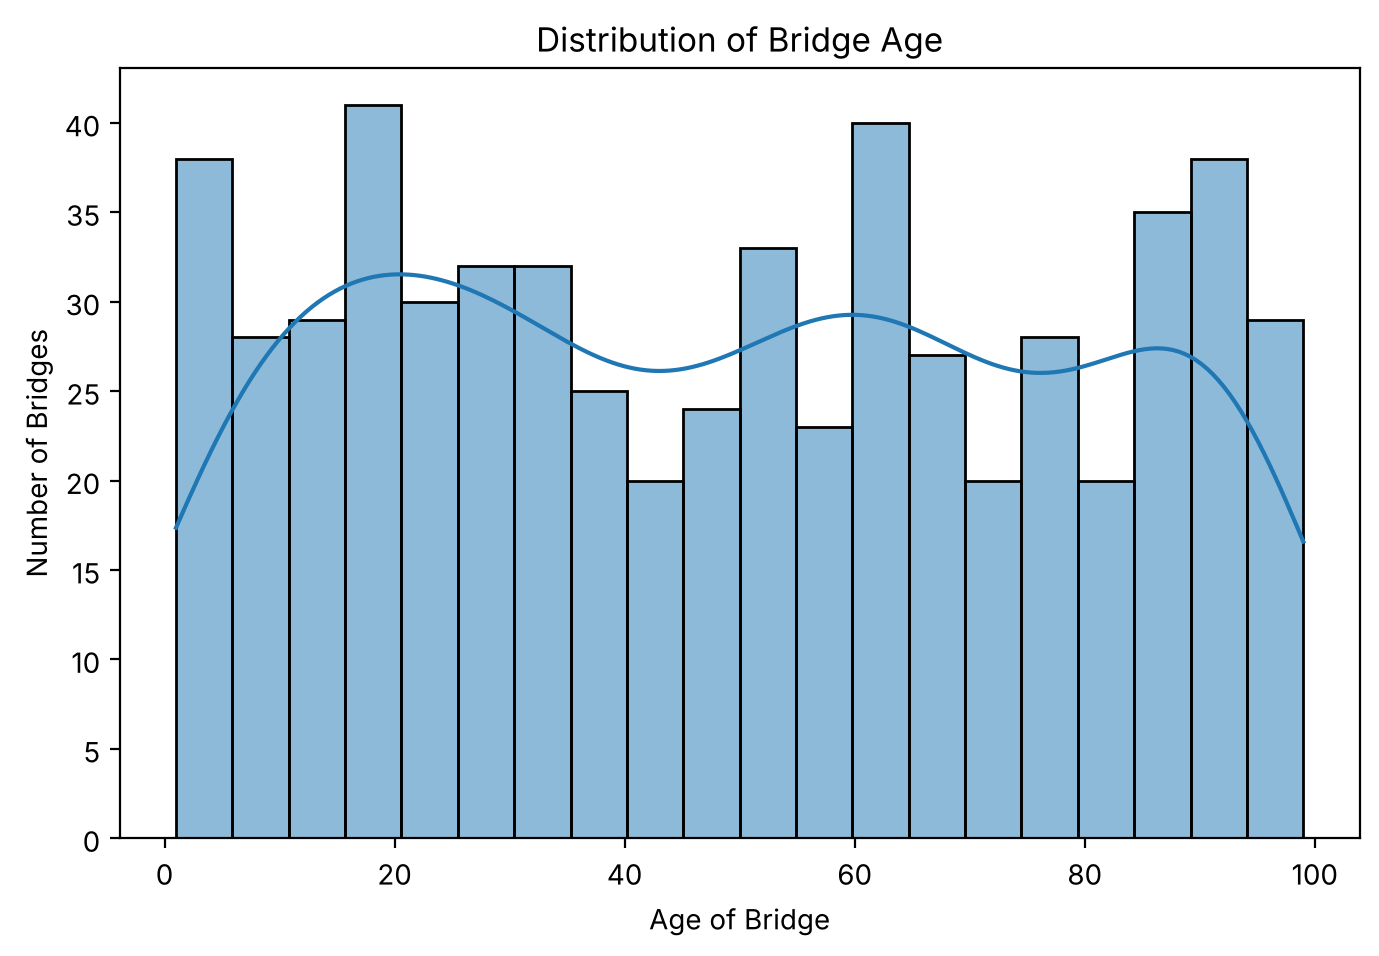

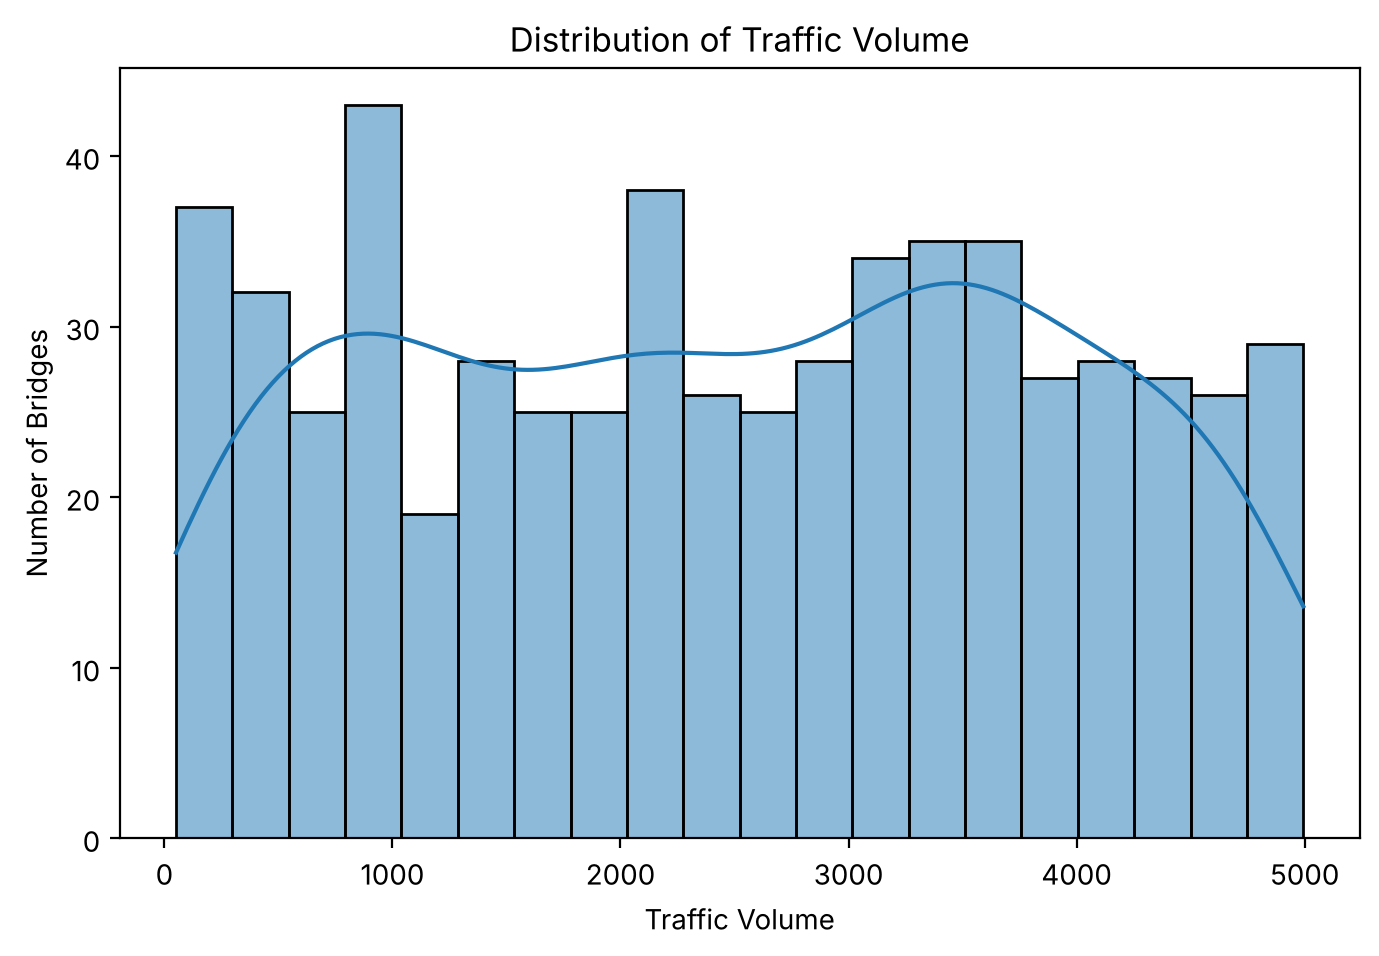

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Age of Bridge distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["age_of_bridge"], bins=20, kde=True)
plt.title("Distribution of Bridge Age")
plt.xlabel("Age of Bridge")
plt.ylabel("Number of Bridges")
plt.show()

# Traffic Volume distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["traffic_volume"], bins=20, kde=True)
plt.title("Distribution of Traffic Volume")
plt.xlabel("Traffic Volume")
plt.ylabel("Number of Bridges")
plt.show()

In [12]:
print("\nSkewness:")
print("Age of Bridge:", df["age_of_bridge"].skew())
print("Traffic Volume:", df["traffic_volume"].skew())


Skewness:
Age of Bridge: 0.05146634909220759
Traffic Volume: -0.025842901215260488


Both numerical features have skewness close to zero (about 0.05 and -0.03), so the distributions are approximately symmetric. No skewness transformation is required.

### 4.2 Bivariate Analysis (Feature vs Target)

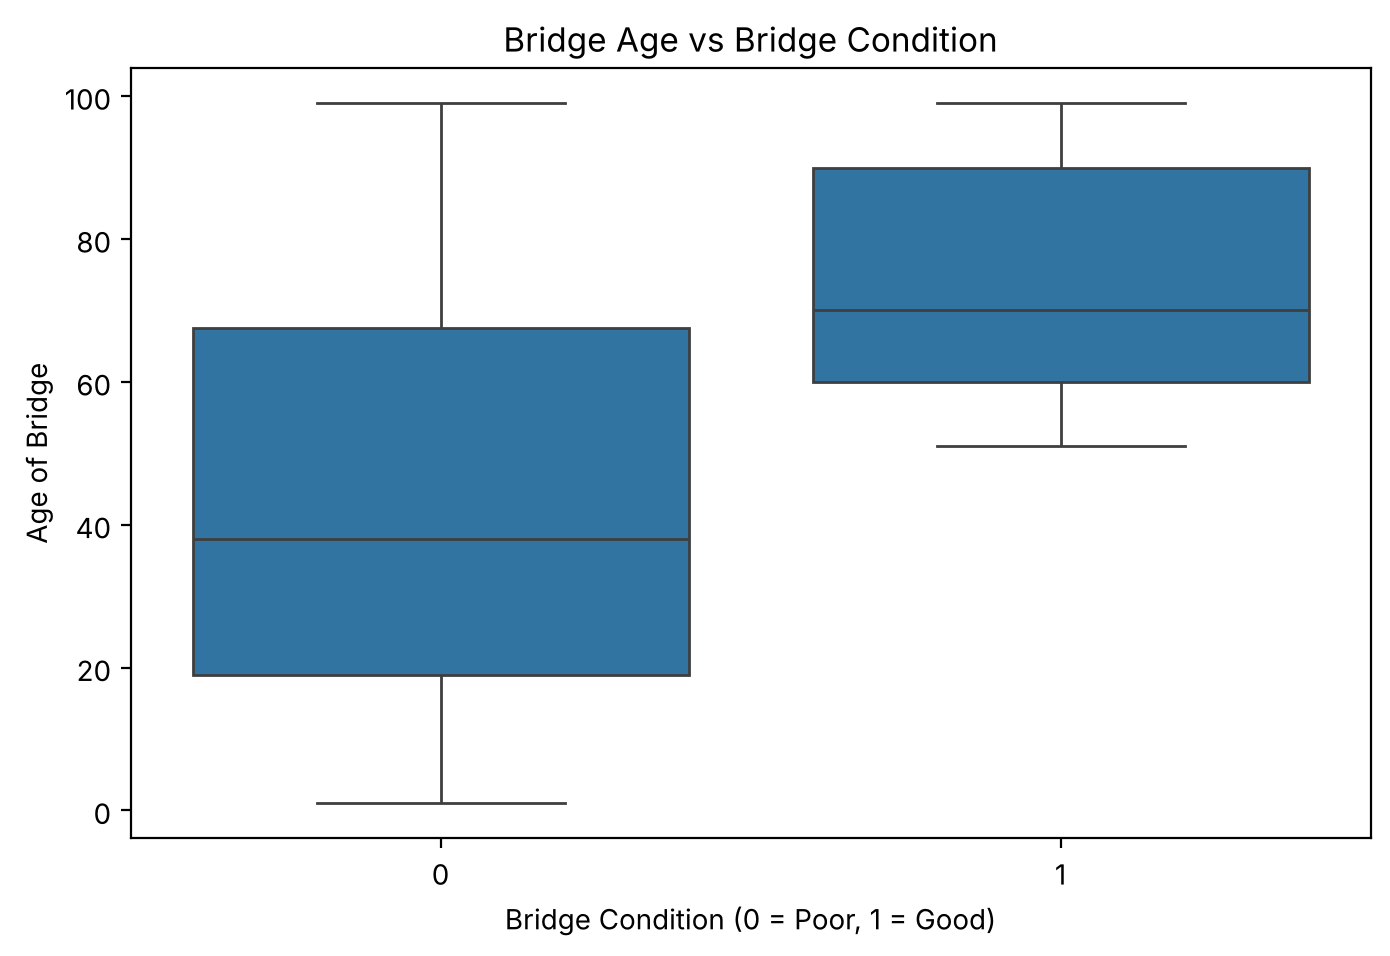

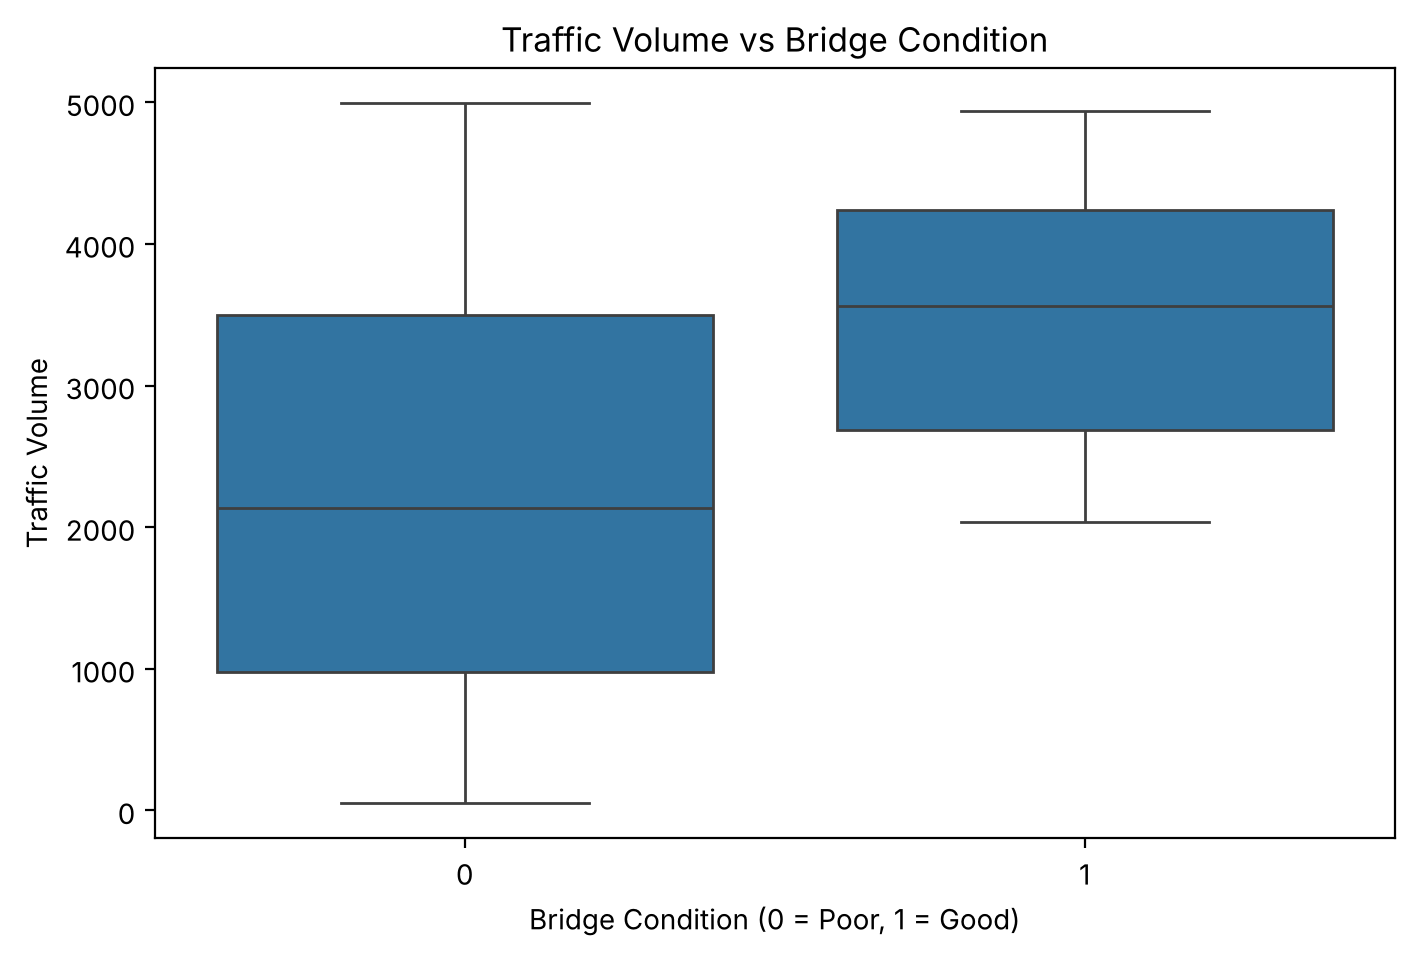

                  age_of_bridge  traffic_volume
bridge_condition                               
0                          43.8          2275.9
1                          74.0          3496.5


In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="bridge_condition", y="age_of_bridge", data=df)
plt.title("Bridge Age vs Bridge Condition")
plt.xlabel("Bridge Condition (0 = Poor, 1 = Good)")
plt.ylabel("Age of Bridge")
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(x="bridge_condition", y="traffic_volume", data=df)
plt.title("Traffic Volume vs Bridge Condition")
plt.xlabel("Bridge Condition (0 = Poor, 1 = Good)")
plt.ylabel("Traffic Volume")
plt.show()

print(df.groupby("bridge_condition")[["age_of_bridge", "traffic_volume"]].mean().round(1))

Bridges labelled good (1) are **older** (mean about 74 years vs 44) and carry **more traffic** (about 3,496 vs 2,276) than poor ones. This is the opposite of engineering intuition, so confirm with the data owner that 1 = Good before modelling.

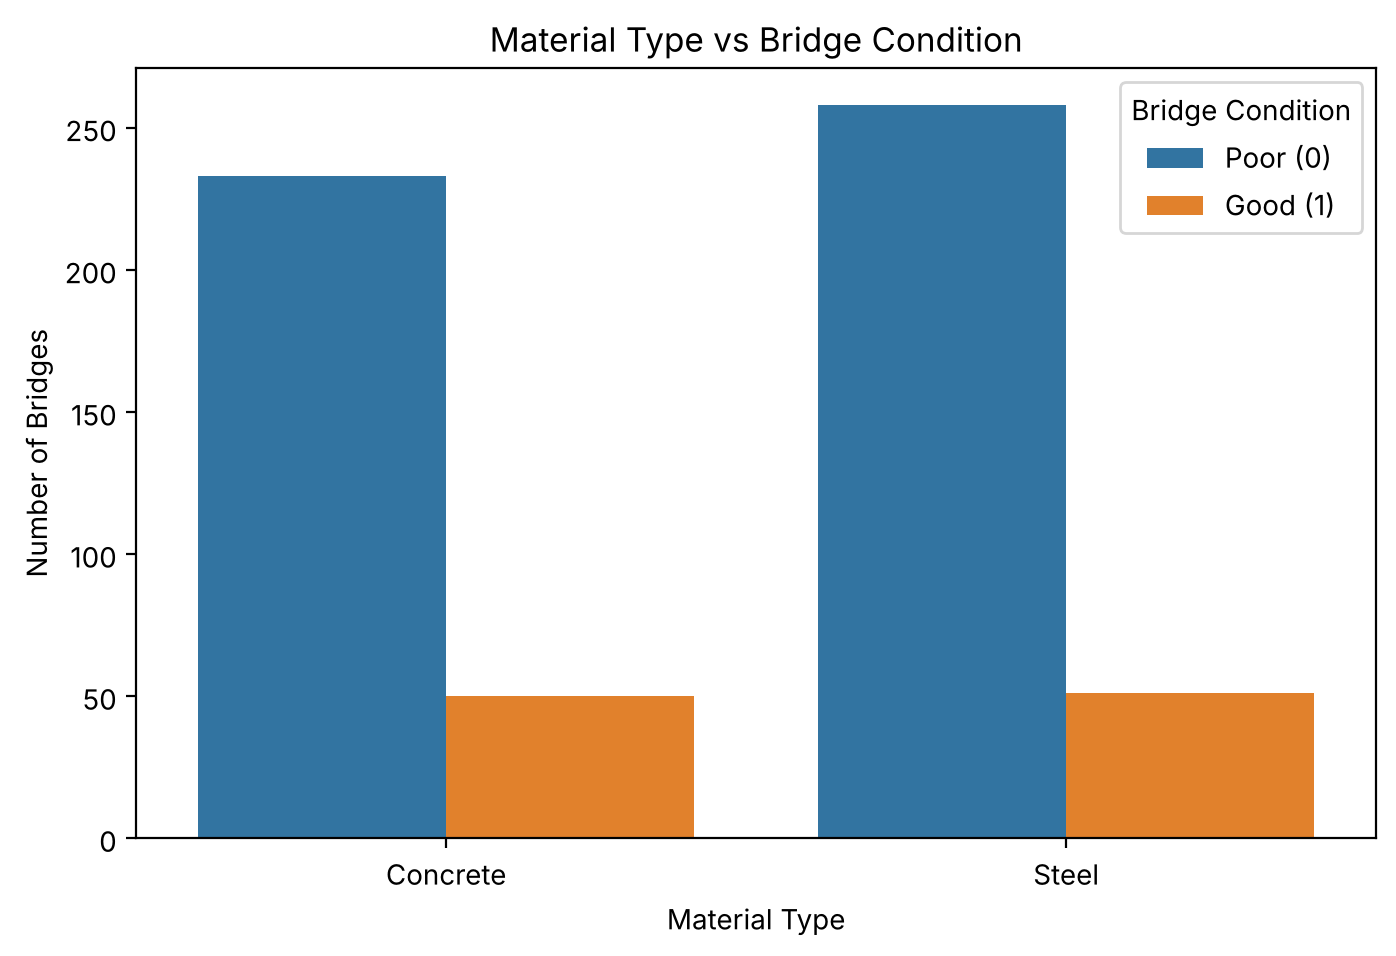

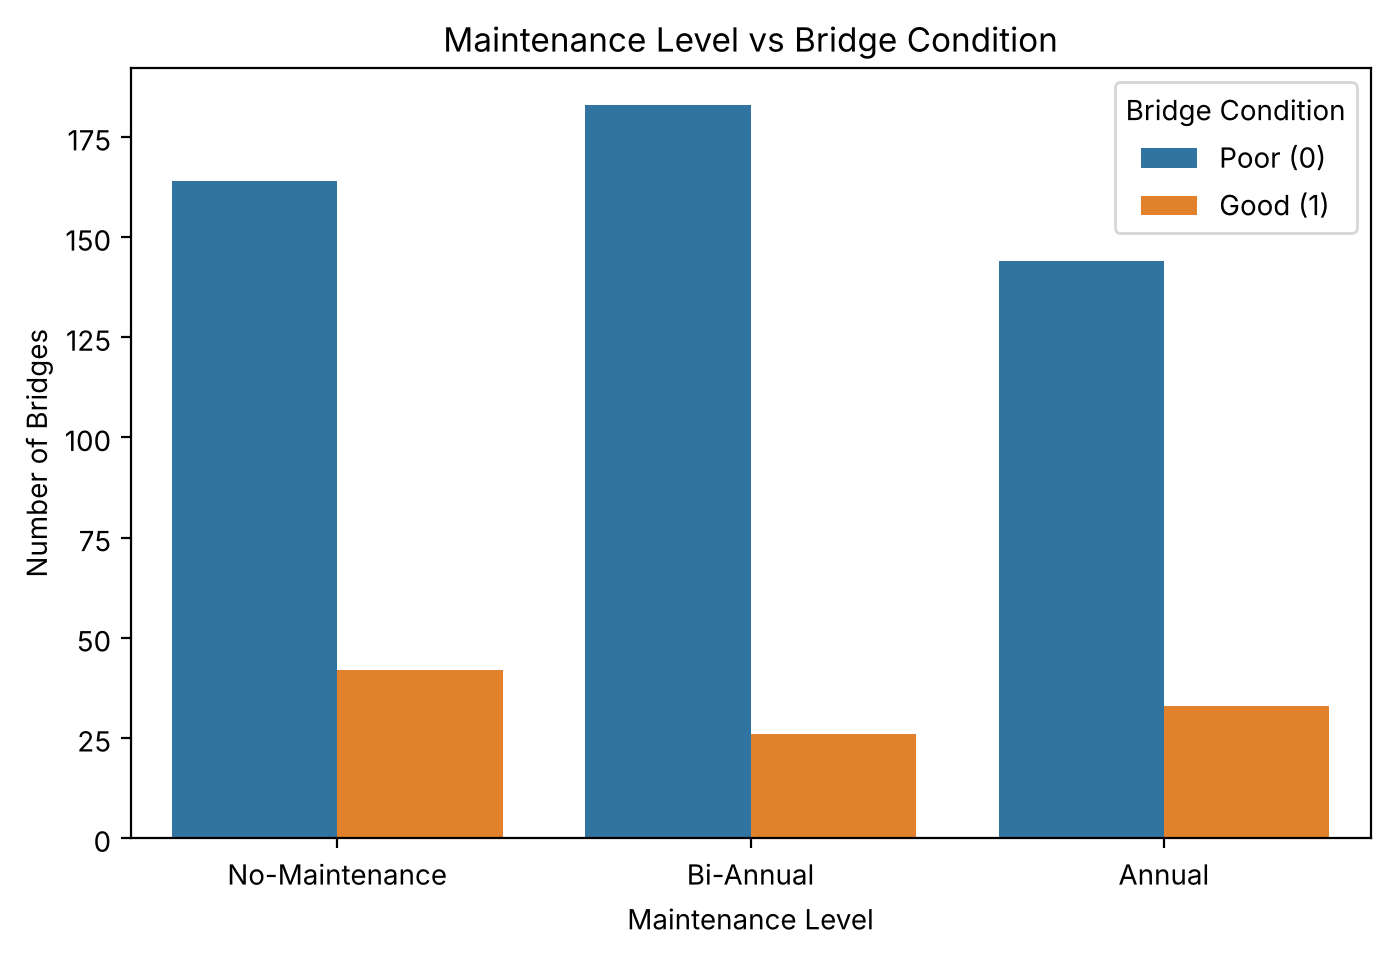


Share of good bridges by category:
material_type
Concrete    0.177
Steel       0.165
Name: bridge_condition, dtype: float64
maintenance_level
Annual            0.186
Bi-Annual         0.124
No-Maintenance    0.204
Name: bridge_condition, dtype: float64


In [14]:
plt.figure(figsize=(8, 5))
sns.countplot(x="material_type", hue="bridge_condition", data=df)
plt.title("Material Type vs Bridge Condition")
plt.xlabel("Material Type")
plt.ylabel("Number of Bridges")
plt.legend(title="Bridge Condition", labels=["Poor (0)", "Good (1)"])
plt.show()

plt.figure(figsize=(8, 5))
sns.countplot(x="maintenance_level", hue="bridge_condition", data=df)
plt.title("Maintenance Level vs Bridge Condition")
plt.xlabel("Maintenance Level")
plt.ylabel("Number of Bridges")
plt.legend(title="Bridge Condition", labels=["Poor (0)", "Good (1)"])
plt.show()

print("\nShare of good bridges by category:")
print(df.groupby("material_type")["bridge_condition"].mean().round(3))
print(df.groupby("maintenance_level")["bridge_condition"].mean().round(3))

Material type has almost no effect (about 17.7% of concrete bridges are good vs 16.5% of steel). Maintenance level has a weak and unexpected effect: Bi-Annual has the lowest good share (about 12%), while No-Maintenance (about 20%) and Annual (about 19%) are higher.

### 4.3 Multivariate Analysis

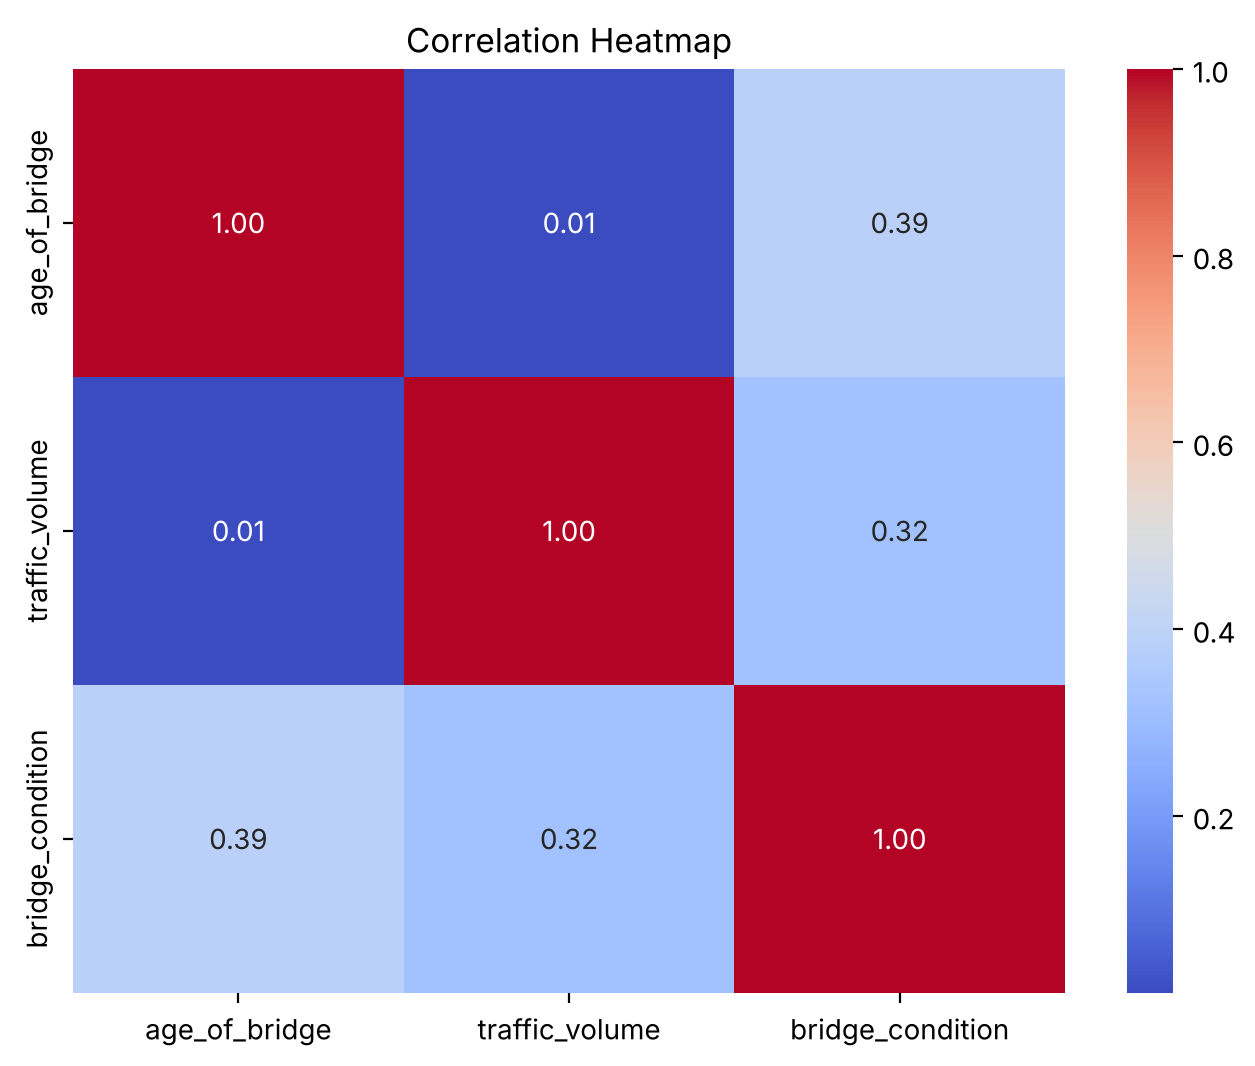

In [15]:
plt.figure(figsize=(8, 6))

correlation = df[["age_of_bridge", "traffic_volume", "bridge_condition"]].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

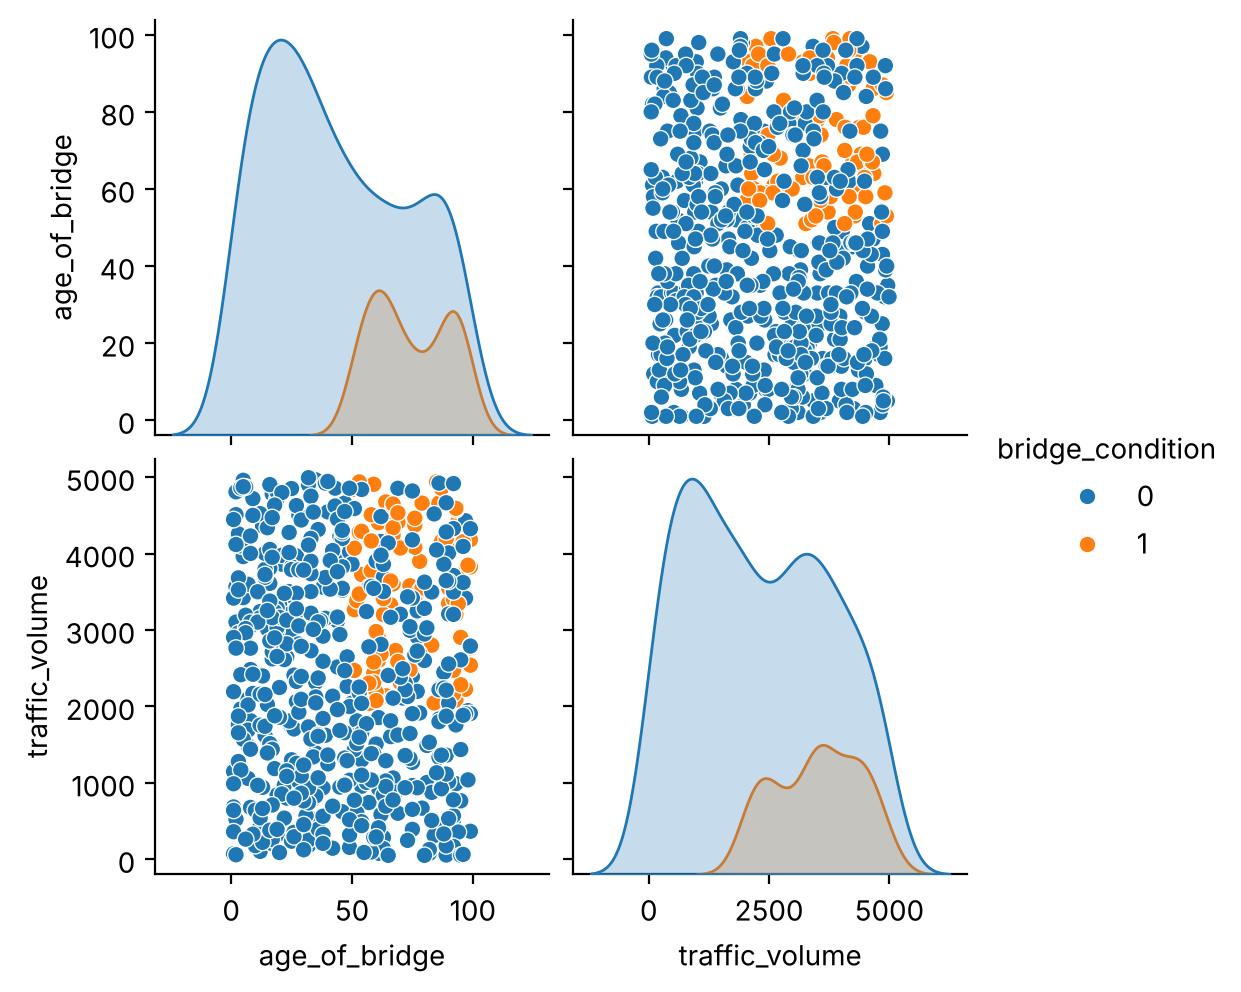

In [16]:
sns.pairplot(df[["age_of_bridge", "traffic_volume", "bridge_condition"]], hue="bridge_condition")
plt.show()

Correlation with the target is +0.39 for age and +0.32 for traffic. Age and traffic are almost uncorrelated with each other (about 0.01), so there is no multicollinearity. In the pairplot, good bridges cluster in the high-age, high-traffic corner, so a non-linear model may capture the pattern better than a linear one.

## Step 5: Outlier Detection & Treatment

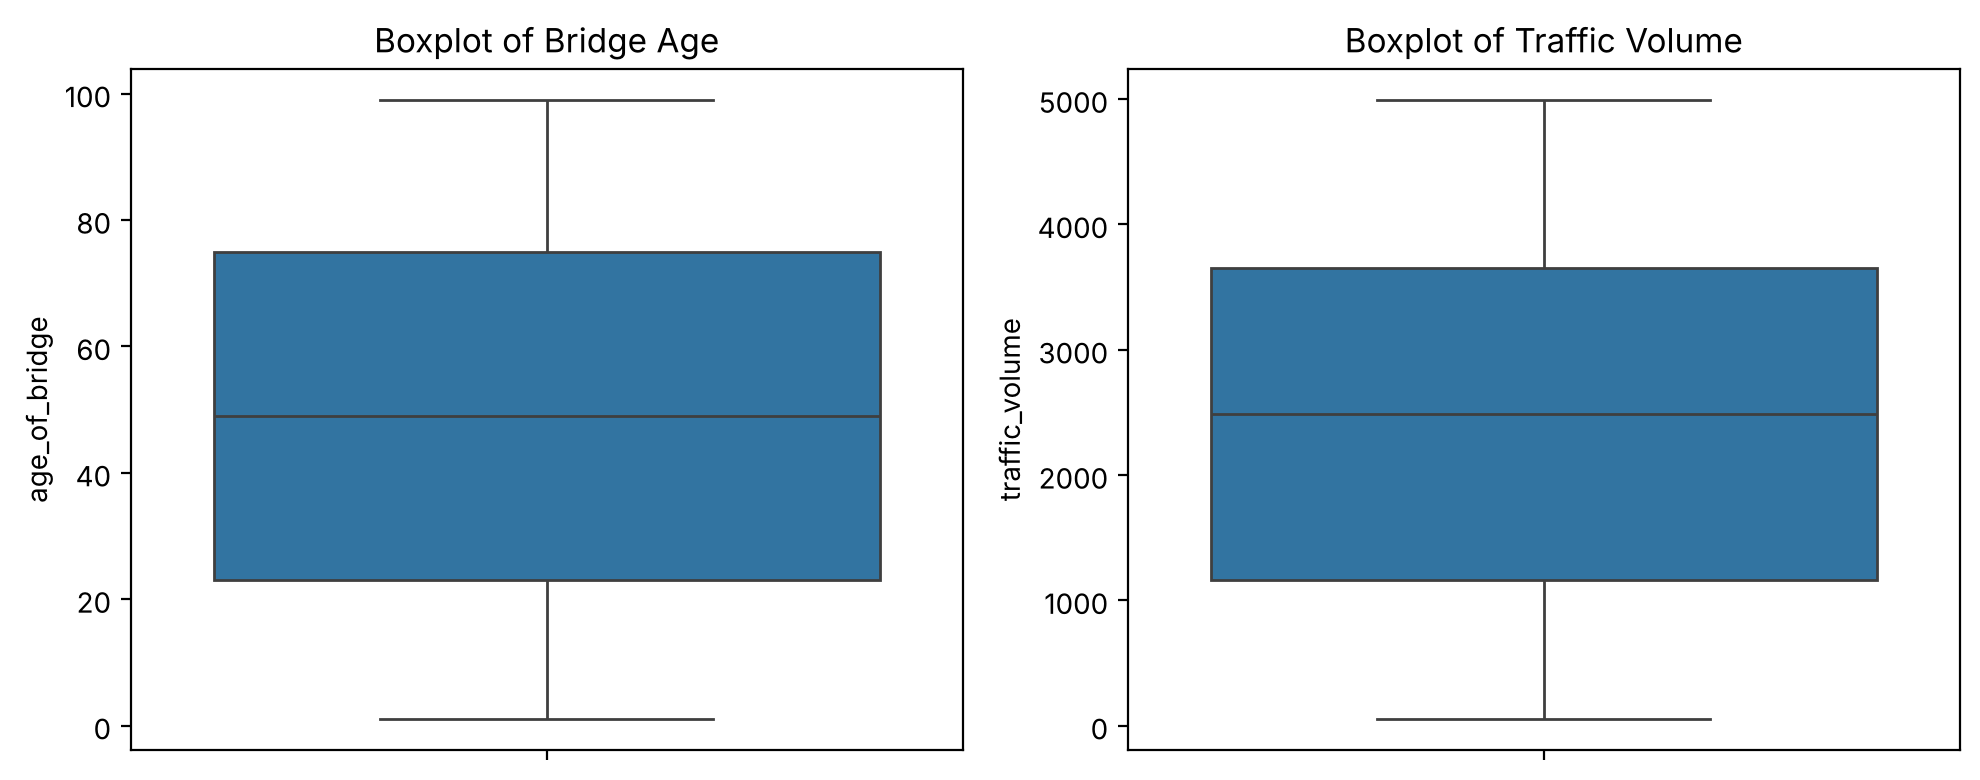

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=df["age_of_bridge"], ax=ax[0])
ax[0].set_title("Boxplot of Bridge Age")
sns.boxplot(y=df["traffic_volume"], ax=ax[1])
ax[1].set_title("Boxplot of Traffic Volume")
plt.tight_layout()
plt.show()

In [18]:
# Function to detect outliers using IQR and Z-score
def detect_outliers(column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    iqr_outliers = df[(df[column] < lower_limit) | (df[column] > upper_limit)]
    z = (df[column] - df[column].mean()) / df[column].std()

    print(f"\n{column}")
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("IQR outliers:", len(iqr_outliers))
    print("Z-score (>3) outliers:", (z.abs() > 3).sum())


detect_outliers("age_of_bridge")
detect_outliers("traffic_volume")


age_of_bridge
Lower Limit: -55.0
Upper Limit: 153.0
IQR outliers: 0
Z-score (>3) outliers: 0

traffic_volume
Lower Limit: -2570.875
Upper Limit: 7392.125
IQR outliers: 0
Z-score (>3) outliers: 0


Both the IQR and Z-score methods find **0 outliers** in either feature, and the boxplots confirm it. No removal, capping or transformation is needed.

## Step 6: Feature Encoding

In [19]:
df_encoded = pd.get_dummies(
    df,
    columns=["material_type", "maintenance_level"],
    drop_first=True,
    dtype=int
)

print("\nDataset after Encoding:")
print(df_encoded.head())

print("\nNew Columns:")
print(df_encoded.columns.tolist())


Dataset after Encoding:
   age_of_bridge  traffic_volume  bridge_condition  material_type_Steel  \
0             80              60                 0                    0   
1             44            2516                 0                    1   
2             61            4406                 1                    0   
3             93            2082                 1                    1   
4             62            4159                 0                    1   

   maintenance_level_Bi-Annual  maintenance_level_No-Maintenance  
0                            0                                 1  
1                            1                                 0  
2                            0                                 0  
3                            0                                 1  
4                            0                                 1  

New Columns:
['age_of_bridge', 'traffic_volume', 'bridge_condition', 'material_type_Steel', 'maintenance_level_Bi-Annual'

One-Hot Encoding is used because neither categorical feature has a numeric order that Label Encoding could represent safely. `drop_first=True` removes one redundant column per feature to avoid perfect collinearity. The baseline categories are Concrete and Annual.

## Step 7: Train-Test Split

In [20]:
from sklearn.model_selection import train_test_split

# Features and target
X = df_encoded.drop("bridge_condition", axis=1)
y = df_encoded["bridge_condition"]

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


Training Data Shape:

 (473, 5)
Testing Data Shape: (119, 5)


An 80/20 stratified split keeps the good/poor ratio (about 17% good) the same in both sets. The split is done **before scaling** so the scaler only learns from training data.

## Step 8: Feature Scaling

In [21]:
from sklearn.preprocessing import StandardScaler

numerical_features = ["age_of_bridge", "traffic_volume"]

scaler = StandardScaler()

# Copy the original train/test DataFrames
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit on training data only, then apply to both
X_train_scaled[numerical_features] = scaler.fit_transform(X_train[numerical_features])
X_test_scaled[numerical_features] = scaler.transform(X_test[numerical_features])

print("\nFinal Training Data:")
print(X_train_scaled.head())


Final Training Data:
     age_of_bridge  traffic_volume  material_type_Steel  \
128       0.371099       -0.204453                    1   
386       1.395192       -0.305853                    0   
59        0.029734       -0.305144                    0   
497       1.600011       -0.418599                    1   
184      -0.038539       -0.150562                    1   

     maintenance_level_Bi-Annual  maintenance_level_No-Maintenance  
128                            1                                 0  
386                            0                                 1  
59                             0                                 0  
497                            0                                 0  
184                            0                                 1  


Standardization is applied to the two numeric columns only (the binary dummy columns are left unchanged). The scaler is **fit on training data only** to prevent data leakage, so the test set will not have exactly mean 0 and std 1.

## Final Validation

In [22]:
print("===== FINAL SPRINT 1 VALIDATION =====")

print("Training Features:", X_train_scaled.shape)
print("Testing Features:", X_test_scaled.shape)

print("\nTarget Distribution - Training:")
print(y_train.value_counts())

print("\nTarget Distribution - Testing:")
print(y_test.value_counts())

print("\nMissing Values (train/test):", X_train_scaled.isnull().sum().sum(), "/", X_test_scaled.isnull().sum().sum())
print("\nData Types:")
print(X_train_scaled.dtypes)

===== FINAL SPRINT 1 VALIDATION =====
Training Features: (473, 5)
Testing Features: (119, 5)

Target Distribution - Training:
bridge_condition
0    392
1     81
Name: count, dtype: int64

Target Distribution - Testing:
bridge_condition
0    99
1    20
Name: count, dtype: int64

Missing Values (train/test): 0 / 0

Data Types:
age_of_bridge                       float64
traffic_volume                      float64
material_type_Steel                   int64
maintenance_level_Bi-Annual           int64
maintenance_level_No-Maintenance      int64
dtype: object


### Summary of Preprocessing Steps
1. Loaded the data (720 rows, 5 columns) and found no missing values.
2. Removed 128 duplicates (all poor class), standardized column names, fixed a category typo, and saved the clean dataset (592 rows).
3. EDA: age (+0.39) and traffic (+0.32) are the main signals, material type is irrelevant, and the target is imbalanced (about 17% good).
4. No outliers were found, so no treatment was applied.
5. One-Hot Encoded the categorical features (`drop_first=True`).
6. Split 80/20 (stratified), then scaled numeric features with `StandardScaler` fitted on training data only.

**Notes for Sprint 2:** evaluate with precision, recall, F1 and the confusion matrix, consider `class_weight="balanced"`, and try both a linear and a tree-based model.